# Bài thực hành 3 — Phân loại ảnh sử dụng mạng tích chập

MSSV: 24521185
Họ và tên: Nguyễn Anh Nguyên

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam, SGD, Lion
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

## Đọc dữ liệu

In [3]:
def load_images_from_folder(folder, img_rows, img_cols):
    images, labels = [], []
    class_names = sorted(name for name in os.listdir(folder) if os.path.isdir(os.path.join(folder, name)))
    for label, class_name in enumerate(class_names):
        class_folder = os.path.join(folder, class_name)
        for filename in sorted(os.listdir(class_folder)):
            if not filename.lower().endswith('.jpg'):
                continue
            img_path = os.path.join(class_folder, filename)
            img = cv2.imread(img_path)
            if img is None:
                img = cv2.cvtColor(np.array(Image.open(img_path).convert('RGB')), cv2.COLOR_RGB2BGR)
            img = cv2.resize(img, (img_rows, img_cols))
            images.append(img)
            labels.append(label)
    return images, labels, class_names

In [4]:
train_folder = '/content/drive/MyDrive/CS231/Dataset/HoaVietNam2027/train'
test_folder = '/content/drive/MyDrive/CS231/Dataset/HoaVietNam2027/test'

img_rows, img_cols = 128, 128

training_images, training_labels, class_names = load_images_from_folder(train_folder, img_rows, img_cols)
test_images, test_labels, _ = load_images_from_folder(test_folder, img_rows, img_cols)
num_classes = len(class_names)

## Chia tập train thành train và val theo tỉ lệ 8:2

In [5]:
train_images, validation_images, train_labels, validation_labels = train_test_split(
    training_images, training_labels, test_size=0.2, train_size=0.8, random_state=42)

## Xử lý dữ liệu

In [6]:
train_images = np.array(train_images).astype('float32') / 255
validation_images = np.array(validation_images).astype('float32') / 255
test_images = np.array(test_images).astype('float32') / 255

train_labels = to_categorical(train_labels, num_classes)
validation_labels = to_categorical(validation_labels, num_classes)
test_labels = to_categorical(test_labels, num_classes)

print(class_names)
print('Train:', train_images.shape, train_labels.shape)
print('Val:', validation_images.shape, validation_labels.shape)
print('Test:', test_images.shape, test_labels.shape)

['Cuc', 'Dao', 'Ga', 'Hong', 'Lan', 'Mai', 'Sen', 'Tho']
Train: (228, 128, 128, 3) (228, 8)
Val: (57, 128, 128, 3) (57, 8)
Test: (92, 128, 128, 3) (92, 8)


## Mạng CNN dựa trên LeNet-5

Tập HoaVietNam2027 có 8 lớp nên lớp Dense cuối dùng 8 nơ-ron.

In [7]:
def build_model():
    model = models.Sequential()
    model.add(layers.Conv2D(6, (3, 3), activation='relu', input_shape=(img_rows, img_cols, 3), padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(16, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(120, activation='relu'))
    model.add(layers.Dense(84, activation='relu'))
    model.add(layers.Dense(num_classes, activation='softmax'))
    return model

build_model().summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 6)    │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │           880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     1,966,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           680 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,978,092 (7.55 MB)

 Trainable params: 1,978,092 (7.55 MB)

 Non-trainable params: 0 (0.00 B)

# Yêu cầu 1
Thực nghiệm với 3 optimizer Adam, SGD, Lion; learning_rate=0.00001, loss='categorical_crossentropy', metrics='accuracy', batch_size=8, epochs=15. Đánh giá 3 mô hình trên tập test.

In [8]:
optimizers = {
    'Adam': Adam,
    'SGD': SGD,
    'Lion': Lion,
}
results = {}

for name, optimizer in optimizers.items():
    print(f'===== {name} =====')
    model = build_model()
    model.compile(optimizer=optimizer(learning_rate=0.00001), loss='categorical_crossentropy', metrics=['accuracy'])
    model.fit(train_images, train_labels, epochs=15, batch_size=8,
              validation_data=(validation_images, validation_labels))

    test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=2)
    predicted_labels = np.argmax(model.predict(test_images), axis=-1)
    results[name] = (test_loss, test_accuracy)
    print(f'Test Accuracy: {test_accuracy}')
    print(f'Test Loss: {test_loss}')
    print(classification_report(np.argmax(test_labels, axis=-1), predicted_labels,
                                target_names=class_names, zero_division=0))

===== Adam =====
Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 179ms/step - accuracy: 0.1140 - loss: 2.0770 - val_accuracy: 0.2105 - val_loss: 2.0558
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.2237 - loss: 2.0456 - val_accuracy: 0.2281 - val_loss: 2.0427
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.3246 - loss: 2.0220 - val_accuracy: 0.2807 - val_loss: 2.0241
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - accuracy: 0.3509 - loss: 1.9972 - val_accuracy: 0.3684 - val_loss: 2.0029
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - accuracy: 0.3904 - loss: 1.9742 - val_accuracy: 0.4561 - val_loss: 1.9803
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 151ms/step - accuracy: 0.4430 - loss: 1.9459 - val_accuracy: 0.3684 - val_loss: 1.9575
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.4430 - loss: 1.9186 - val_accuracy: 0.5263 - val_loss: 1.9315
Epoch 8/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.4781 - loss: 1.8906 - val_

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.1184 - loss: 2.0865 - val_accuracy: 0.1053 - val_loss: 2.1335
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - accuracy: 0.1140 - loss: 2.0853 - val_accuracy: 0.1053 - val_loss: 2.1317
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.1140 - loss: 2.0841 - val_accuracy: 0.1053 - val_loss: 2.1300
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.1140 - loss: 2.0829 - val_accuracy: 0.1053 - val_loss: 2.1282
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.1184 - loss: 2.0817 - val_accuracy: 0.1053 - val_loss: 2.1266
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.1184 - loss: 2.0805 - val_accuracy: 0.1053 - val_loss: 2.1250
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 140ms/step - accuracy: 0.1184 - loss: 2.0794 - val_accuracy: 0.1053 - val_loss: 2.1235
Epoch 8/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.1228 - loss: 2.0784 - val_accuracy: 0.1053 - val_loss:

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 124ms/step - accuracy: 0.1228 - loss: 2.0791 - val_accuracy: 0.2456 - val_loss: 2.0476
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.2105 - loss: 2.0470 - val_accuracy: 0.2456 - val_loss: 2.0278
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - accuracy: 0.2325 - loss: 2.0188 - val_accuracy: 0.2281 - val_loss: 2.0088
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 136ms/step - accuracy: 0.2281 - loss: 1.9806 - val_accuracy: 0.2456 - val_loss: 1.9880
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.2982 - loss: 1.9456 - val_accuracy: 0.3333 - val_loss: 1.9645
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.3465 - loss: 1.9008 - val_accuracy: 0.2982 - val_loss: 1.9372
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - accuracy: 0.3509 - loss: 1.8579 - val_accuracy: 0.3158 - val_loss: 1.9142
Epoch 8/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.4211 - loss: 1.8086 - val_accuracy: 0.4211 

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step 

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
Test Accuracy: 0.3478260934352875
Test Loss: 1.7741656303405762
              precision    recall  f1-score   support

         Cuc       0.19      0.40      0.26        10
         Dao       0.60      0.25      0.35        12
          Ga       0.37      0.67      0.48        15
        Hong       0.50      0.13      0.21        15
         Lan       0.50      0.20      0.29        10
         Mai       0.33      0.70      0.45        10
         Sen       0.00      0.00      0.00        10
         Tho       0.50      0.40      0.44        10

    accuracy                           0.35        92
   macro avg       0.37      0.34      0.31        92
weighted avg       0.39      0.35      0.31        92



In [9]:
for name, (test_loss, test_accuracy) in results.items():
    print(f'{name:<5} Test Accuracy = {test_accuracy:.4f}  Test Loss = {test_loss:.4f}')

best_optimizer = max(results, key=lambda name: results[name][1])
print('Optimizer phù hợp nhất:', best_optimizer)

Adam  Test Accuracy = 0.4674  Test Loss = 1.8044
SGD   Test Accuracy = 0.1196  Test Loss = 2.0815
Lion  Test Accuracy = 0.3478  Test Loss = 1.7742
Optimizer phù hợp nhất: Adam


# Yêu cầu 2
Huấn luyện lại với optimizer tốt nhất ở yêu cầu 1, có sử dụng ReduceLROnPlateau và EarlyStopping. Các tham số khác giữ như yêu cầu 1.

In [10]:
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

model = build_model()
model.compile(optimizer=optimizers[best_optimizer](learning_rate=0.00001),
              loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=15, batch_size=8,
                    validation_data=(validation_images, validation_labels),
                    callbacks=[reduce_lr, early_stopping])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.1754 - loss: 2.0718 - val_accuracy: 0.2281 - val_loss: 2.0535 - learning_rate: 1.0000e-05
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.2632 - loss: 2.0375 - val_accuracy: 0.2456 - val_loss: 2.0290 - learning_rate: 1.0000e-05
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step - accuracy: 0.3114 - loss: 2.0083 - val_accuracy: 0.2807 - val_loss: 2.0032 - learning_rate: 1.0000e-05
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.3114 - loss: 1.9793 - val_accuracy: 0.2982 - val_loss: 1.9771 - learning_rate: 1.0000e-05
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.3202 - loss: 1.9481 - val_accuracy: 0.2982 - val_loss: 1.9513 - learning_rate: 1.0000e-05
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 138ms/step - accuracy: 0.3246 - loss: 1.9190 - val_accuracy: 0.2982 - val_loss: 1.9237 - learning_rate: 1.0000e-05
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.

## Biểu đồ độ chính xác và loss trong quá trình huấn luyện

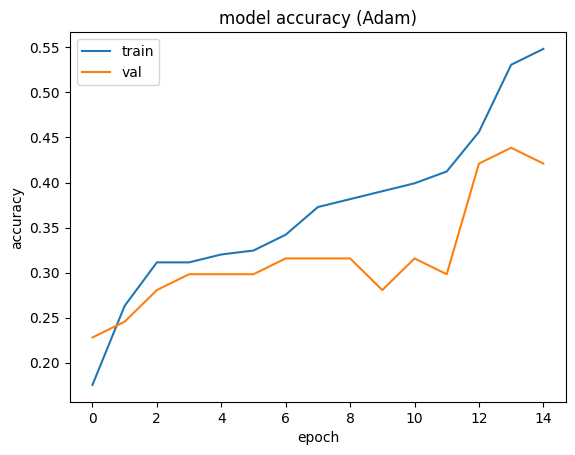

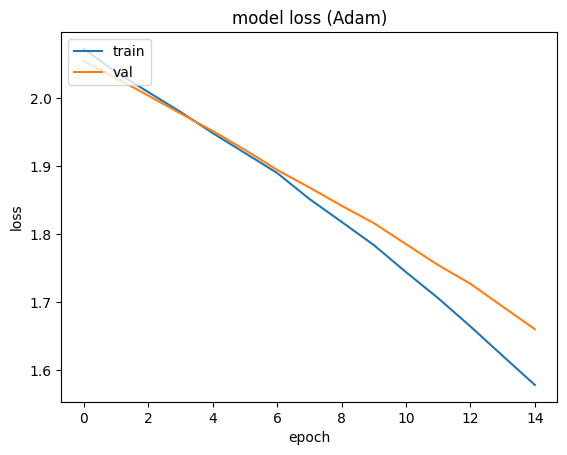

In [11]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title(f'model accuracy ({best_optimizer})')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title(f'model loss ({best_optimizer})')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

## Đánh giá trên tập test

In [12]:
test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=2)
print(f'Test Accuracy: {test_accuracy}')
print(f'Test Loss: {test_loss}')

predicted_labels = np.argmax(model.predict(test_images), axis=-1)
print(classification_report(np.argmax(test_labels, axis=-1), predicted_labels,
                            target_names=class_names, zero_division=0))

3/3 - 0s - 107ms/step - accuracy: 0.3370 - loss: 1.7085
Test Accuracy: 0.33695653080940247
Test Loss: 1.7085129022598267
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 154ms/step
              precision    recall  f1-score   support

         Cuc       0.21      0.90      0.34        10
         Dao       0.00      0.00      0.00        12
          Ga       0.45      0.67      0.54        15
        Hong       0.57      0.27      0.36        15
         Lan       0.17      0.20      0.18        10
         Mai       1.00      0.40      0.57        10
         Sen       0.50      0.10      0.17        10
         Tho       0.50      0.10      0.17        10

    accuracy                           0.34        92
   macro avg       0.43      0.33      0.29        92
weighted avg       0.43      0.34      0.30        92

